# BÁO CÁO THỰC HÀNH TRANSFORMER
## Dịch Việt → Anh qua câu “Tôi đang học thạc sĩ công nghệ thông tin”

**Học phần:** PRN501 · **Hình thức:** notebook giải thích và thực nghiệm · **Ngày biên soạn:** 07/11/2026

> **Câu nguồn:** Tôi đang học thạc sĩ công nghệ thông tin.  
> **Bản dịch tham chiếu:** I am pursuing a master's degree in information technology.

Notebook trình bày trọn luồng **văn bản → token → embedding + vị trí → encoder → decoder → xác suất → huấn luyện → sinh bản dịch**. Các ô code có chú thích tiếng Việt, bảng trung gian và hình minh họa. Kết quả lưu trong notebook được tạo bằng việc chạy code, không điền xác suất hay loss giả định.

**Phạm vi thực nghiệm:** chỉ một cặp câu. Phần A dùng NumPy để quan sát phép tính; phần B dùng PyTorch để học toàn bộ tham số của một Transformer nhỏ. Sinh đúng câu đã học chỉ cho thấy mô hình ghi nhớ được mẫu, chưa chứng minh khả năng dịch tổng quát.

**Phụ trách mục 1–4:** `huy26ms23411@fsb.edu.vn` (cell 0–9, chỉ số bắt đầu từ 0): bài toán dịch, tokenization, vocabulary và luồng kiến trúc tổng thể.

## 1. Mục tiêu và cách sử dụng

Sau bài này, người học có thể giải thích Q/K/V, tính scaled dot-product attention, phân biệt ba attention trong encoder–decoder, hiểu causal mask và teacher forcing, rồi theo dõi mô hình sinh từng token.

| Phần | Nội dung | Thư viện |
|---|---|---|
| A · mục 2–10 | Tiền xử lý và forward từng bước, chưa học | NumPy, Matplotlib |
| B · mục 11–14 | Transformer có 4 head, autograd, Adam, greedy decoding | PyTorch |
| C · mục 15–18 | Chẩn đoán, lưu/nạp, thảo luận và kết luận | Thư viện trên |

**Cách chạy:** mở bằng Jupyter, VS Code hoặc Google Colab; chọn Python 3.10 trở lên, chạy **Run All** từ trên xuống. Không cần Google Drive, API key, tập dữ liệu ngoài hay checkpoint có sẵn. CPU đủ cho ví dụ nhỏ. Ô cài đặt dưới đây được để dưới dạng chú thích; chỉ bỏ `#` khi môi trường thiếu thư viện. Khi dùng máy khác, số cuối có thể chênh lệch nhỏ.

**Luồng cần nắm:** văn bản được chuẩn hóa rồi tách token, ánh xạ sang ID và tra
embedding; thông tin vị trí được cộng vào vector trước encoder/decoder. Encoder
tạo memory cho câu nguồn. Decoder kết hợp prefix câu đích với memory, tạo logits
trên từ điển tiếng Anh; softmax chuyển logits thành xác suất. Khi huấn luyện, nhãn
tham chiếu tạo loss để cập nhật trọng số. Khi sinh, mô hình nối token vừa dự đoán
vào prefix cho đến `<eos>` hoặc giới hạn độ dài, không nhận sẵn cả câu tham chiếu.
Các cell 0–9 chuẩn bị dữ liệu và minh họa kiến trúc, chưa thực hiện vòng học.


In [1]:
# Phụ trách: huy26ms23411@fsb.edu.vn | Môi trường NumPy và hàm hiển thị bảng
# Chỉ chạy nếu thiếu thư viện; sau khi cài hãy khởi động lại kernel.
# %pip install numpy matplotlib torch

# math hỗ trợ phép toán; re tách token; unicodedata chuẩn hóa cách mã hóa dấu.
# random và NumPy được seed riêng; seed này không tự đặt seed cho PyTorch ở phần B.
import math
import random
import re
import unicodedata
import platform
import html
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Cố định ngẫu nhiên để các phép minh họa lặp lại được trong cùng môi trường.
# set_printoptions chỉ làm tròn số khi IN, không đổi độ chính xác phép tính.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({'figure.dpi': 130, 'font.family': 'DejaVu Sans',
                     'axes.spines.top': False, 'axes.spines.right': False})

# Bảng phục vụ quan sát dữ liệu trung gian, không tham gia forward/backprop.
# html.escape hiển thị <pad>/<eos> như văn bản, tránh bị hiểu thành thẻ HTML.
def table(headers, rows):
    """Hiển thị bảng HTML, không cần cài pandas."""
    head = ''.join('<th>' + html.escape(str(x)) + '</th>' for x in headers)
    body = ''.join('<tr>' + ''.join('<td>' + html.escape(str(x)) + '</td>'
                   for x in row) + '</tr>' for row in rows)
    display(HTML('<table><thead><tr>' + head + '</tr></thead><tbody>' + body + '</tbody></table>'))

print('Python:', platform.python_version(), '| NumPy:', np.__version__)

Python: 3.13.1 | NumPy: 2.5.3


## 2. Phân tích câu nguồn và lựa chọn bản dịch

Câu nguồn được sử dụng xuyên suốt báo cáo là **“Tôi đang học thạc sĩ công nghệ thông tin”**. Mô hình nhận trực tiếp câu này; tiền xử lý chỉ chuẩn hóa Unicode NFC, chuyển về chữ thường và tách token, không thay đổi từ hay sửa chính tả.

| Cụm tiếng Việt | Cách diễn đạt tiếng Anh | Giải thích |
|---|---|---|
| Tôi | I | Chủ thể ở ngôi thứ nhất |
| đang học | am pursuing | Diễn đạt quá trình đang theo học một chương trình |
| thạc sĩ | a master's degree | Bằng/chương trình thạc sĩ |
| công nghệ thông tin | in information technology | Lĩnh vực theo học |

Một cách diễn đạt khác là **“I am studying for a master's degree in information technology.”** Bài thực nghiệm chọn duy nhất bản tham chiếu dùng **pursuing** để nhất quán. Không dịch “thạc sĩ” thành một từ rời rồi ghép máy móc; số token nguồn và đích không cần bằng nhau.

Các cụm trong bảng là đối chiếu nghĩa do người viết giải thích, không phải một
ma trận căn chỉnh do attention học được. Hai ngôn ngữ khác trật tự và cách diễn đạt;
một cụm nguồn có thể ứng với nhiều token đích. Bản tham chiếu là nhãn huấn luyện
được chọn cho ví dụ, không phải đáp án duy nhất đúng về ngôn ngữ.


In [2]:
# Phụ trách: huy26ms23411@fsb.edu.vn | Câu nguồn và tokenization giữ dấu tiếng Việt
# SOURCE là đầu vào tiếng Việt; REFERENCE là bản dịch để tạo nhãn huấn luyện.
# Dấu chấm cuối câu Anh sẽ bị regex bỏ, không trở thành token riêng.
SOURCE = 'Tôi đang học thạc sĩ công nghệ thông tin'
REFERENCE = "I am pursuing a master's degree in information technology."

# Cùng một quy trình chuẩn hóa cho cả hai ngôn ngữ, nhưng tạo vocabulary riêng sau đó.
# NFC thống nhất các cách biểu diễn dấu tương đương, không loại dấu/phiên âm tiếng Việt.
# lower đưa I/Tôi về i/tôi; replace thống nhất apostrophe cong ’ thành dấu ASCII '.
def tokenize(text):
    # NFC gom các dấu Unicode về dạng nhất quán; giữ dấu tiếng Việt.
    text = unicodedata.normalize('NFC', text).lower().replace('’', "'")
    # Giữ apostrophe bên trong master's; bỏ dấu câu ở cuối.
    # [^\W_]+ khớp ký tự chữ/số Unicode, loại underscore và ký tự không phải word.
    # (?:'[^\W_]+)* giữ các nhóm apostrophe nằm giữa chữ/số, nên master's là một token.
    # Regex lấy các cụm khớp và bỏ dấu câu/khoảng trắng; không phải tokenizer subword.
    # Với câu Việt này, khoảng trắng tách âm tiết: thạc/sĩ và công/nghệ/thông/tin.
    return re.findall(r"[^\W_]+(?:'[^\W_]+)*", text, flags=re.UNICODE)

# Sau chuẩn hóa: nguồn 9 token, đích cũng 9 token ở ví dụ này chỉ là trùng hợp.
# Dịch máy không yêu cầu số token nguồn bằng số token đích.
src_words = tokenize(SOURCE)
tgt_words = tokenize(REFERENCE)
# Assert kiểm tra đúng dữ liệu đầu vào mong đợi; đây không phải kiểm tra chất lượng dịch.
assert src_words == ['tôi', 'đang', 'học', 'thạc', 'sĩ', 'công', 'nghệ', 'thông', 'tin']
print('Câu nguồn :', SOURCE)
print('Chuẩn hóa :', ' '.join(src_words))
print('Nguồn     :', src_words, '|', len(src_words), 'âm tiết/token')
print('Đích      :', tgt_words, '|', len(tgt_words), 'token')

Câu nguồn : Tôi đang học thạc sĩ công nghệ thông tin
Chuẩn hóa : tôi đang học thạc sĩ công nghệ thông tin
Nguồn     : ['tôi', 'đang', 'học', 'thạc', 'sĩ', 'công', 'nghệ', 'thông', 'tin'] | 9 âm tiết/token
Đích      : ['i', 'am', 'pursuing', 'a', "master's", 'degree', 'in', 'information', 'technology'] | 9 token


### 2.1. Token không đồng nghĩa với từ hoàn chỉnh

Ví dụ dùng cách tách theo đơn vị cách nhau bởi khoảng trắng, giữ apostrophe trong `master's`. Tiếng Việt có **9 token nội dung**: `tôi`, `đang`, `học`, `thạc`, `sĩ`, `công`, `nghệ`, `thông`, `tin`. Code ở ô trên kiểm tra số lượng này. Cụm `công nghệ thông tin` gồm bốn âm tiết; `thạc sĩ` gồm hai âm tiết. Các đơn vị này không phải kết quả phân đoạn từ tiếng Việt chuyên dụng. Thực tế thường dùng tokenizer subword được học từ dữ liệu.

Ở đây “token” là đơn vị mà code thực sự xử lý, không mặc định là từ hoàn chỉnh.
Regex còn nhận chữ số và xử lý dấu câu nên chính xác hơn cách gọi “chỉ split bằng
khoảng trắng”. Với câu đang dùng, kết quả tương ứng chín âm tiết tiếng Việt.
Việc giữ `master's` liền nhau là quy ước của tokenizer này, không phải quy tắc bắt
buộc của mọi tokenizer tiếng Anh.


## 3. Từ điển, token đặc biệt và dịch phải

Hai ngôn ngữ có **từ điển riêng**; cùng một số ID ở hai từ điển không có nghĩa cùng một nội dung.

| Token | Vai trò |
|---|---|
| `<pad>` | Đệm nếu mở rộng sang batch có độ dài khác nhau |
| `<unk>` | Đại diện token ngoài từ điển |
| `<bos>` | Bắt đầu chuỗi đích |
| `<eos>` | Kết thúc chuỗi |

Encoder nhận `nguồn + <eos>`. Decoder trong huấn luyện nhận `<bos> + đích`, còn nhãn là `đích + <eos>`. Như vậy tại vị trí có input `am`, nhãn cần dự đoán là `pursuing`, không phải `am`.

**Ví dụ dịch phải ở hai vị trí đầu:** decoder nhận `<bos>` thì nhãn là `i`;
decoder nhận `i` thì nhãn là `am`. Ở vị trí cuối, decoder nhận `technology` và nhãn
là `<eos>`. Trong teacher forcing, prefix dùng token đích thật; causal mask ở phần
sau chặn việc nhìn token tương lai. Dịch phải và mask phải phối hợp để không rò rỉ
nhãn cần dự đoán.

Hai từ điển được dựng chỉ từ cặp câu minh họa, không bao phủ ngôn ngữ tổng quát.
`<unk>` dành cho token ngoài từ điển, nhưng phép tra cứu trực tiếp trong cell 7 chỉ
mã hóa các token vừa đưa vào từ điển; nó không tự thay token lạ bằng `<unk>`. Khi
mở rộng dữ liệu cần đường mã hóa có fallback và chỉ học từ điển trên tập train.


In [3]:
# Phụ trách: huy26ms23411@fsb.edu.vn | Hai vocabulary và ba chuỗi ID
# Cả hai từ điển dùng chung QUY ƯỚC token đặc biệt: PAD=0, UNK=1, BOS=2, EOS=3.
# <pad> dùng đệm, <unk> dùng token lạ, <bos> bắt đầu đích, <eos> kết thúc chuỗi.
# Ví dụ một cặp câu chưa cần padding; khai báo PAD không tự tạo padding mask.
SPECIALS = ['<pad>', '<unk>', '<bos>', '<eos>']
PAD, UNK, BOS, EOS = range(4)

def build_vocab(words):
    # dict.fromkeys giữ thứ tự xuất hiện và loại mục trùng.
    # itos[index] trả token; stoi[token] trả ID. ID là chỉ mục, không mang độ lớn ngữ nghĩa.
    # Token nội dung đầu tiên có ID=4, sau bốn token đặc biệt.
    # Hàm phù hợp dữ liệu ví dụ không chứa token đặc biệt dưới dạng nội dung.
    itos = SPECIALS + list(dict.fromkeys(words))
    return {word: idx for idx, word in enumerate(itos)}, itos

# Tạo độc lập: ID 4 của nguồn là 'tôi', ID 4 của đích là 'i'.
# Cùng số không có nghĩa dùng cùng bảng embedding hay cùng nghĩa trên mọi dữ liệu.
src_stoi, src_itos = build_vocab(src_words)
tgt_stoi, tgt_itos = build_vocab(tgt_words)
# Encoder đọc toàn bộ nội dung nguồn rồi <eos>; không cần <bos> ở nguồn trong thiết kế này.
# Decoder input và label cùng độ dài nhưng lệch nội dung đúng một vị trí.
src_tokens = src_words + ['<eos>']
dec_tokens = ['<bos>'] + tgt_words
label_tokens = tgt_words + ['<eos>']
# Mã hóa thành vector số nguyên một chiều; phần B mới thêm chiều batch và chuyển tensor.
# source_ids=(10,), decoder_ids=(10,), label_ids=(10,) trong đúng ví dụ này.
# Nội dung nguồn/đích cùng 9 token nên S=T=10; mô hình không bắt buộc S=T.
source_ids = np.array([src_stoi[w] for w in src_tokens])
decoder_ids = np.array([tgt_stoi[w] for w in dec_tokens])
label_ids = np.array([tgt_stoi[w] for w in label_tokens])
S, T = len(source_ids), len(decoder_ids)
assert len(src_words) == 9 and S == 10 and T == 10
# Bảng thứ nhất cho phép đối chiếu token Việt với ID; bảng thứ hai kiểm tra input/nhãn.
# Khi sinh thật, chỉ khởi tạo <bos> rồi nối dự đoán, không cấp dec_tokens tham chiếu.
table(['Vị trí', 'Token nguồn', 'ID nguồn'], [(i,w,int(source_ids[i])) for i,w in enumerate(src_tokens)])
table(['Vị trí', 'Decoder input', 'Nhãn cần dự đoán'],
      [(i,x,y) for i,(x,y) in enumerate(zip(dec_tokens,label_tokens))])
print('Số mục từ vựng nguồn/đích:', len(src_itos), len(tgt_itos))
print('Độ dài nguồn/đích có token đặc biệt:', S, T)

Vị trí,Token nguồn,ID nguồn
0,tôi,4
1,đang,5
2,học,6
3,thạc,7
4,sĩ,8
5,công,9
6,nghệ,10
7,thông,11
8,tin,12
9,<eos>,3


Vị trí,Decoder input,Nhãn cần dự đoán
0,<bos>,i
1,i,am
2,am,pursuing
3,pursuing,a
4,a,master's
5,master's,degree
6,degree,in
7,in,information
8,information,technology
9,technology,<eos>


Số mục từ vựng nguồn/đích: 13 13
Độ dài nguồn/đích có token đặc biệt: 10 10


## 4. Kiến trúc tổng thể

Encoder đọc **toàn bộ câu Việt**, tạo memory chứa biểu diễn theo ngữ cảnh. Decoder đọc prefix tiếng Anh và truy xuất memory để dự đoán token kế tiếp. Cả hai dùng attention, residual connection, LayerNorm và FFN.

Phần A chọn **d_model = 4, 1 head, FFN = 8** để dễ xem các vector; mọi trọng số đều ngẫu nhiên. Phần B tạo mô hình mới **d_model = 32, 4 head, FFN = 64**, mỗi bên một block, rồi huấn luyện tất cả tham số. Hai phần dùng cùng dữ liệu nhưng không dùng chung trọng số.

**Vai trò các đường dữ liệu:** encoder self-attention kết hợp các vị trí nguồn
để tạo memory theo ngữ cảnh. Decoder masked self-attention chỉ dùng prefix hợp lệ;
cross-attention lấy query từ decoder, còn key/value được chiếu từ memory nguồn.
Vì vậy số vị trí nguồn và đích có thể khác nhau. Lớp Linear cuối chiếu vector
decoder sang số mục của vocabulary đích, sau đó softmax cho phân bố token kế tiếp.

Phần A chỉ minh họa forward bằng các ma trận NumPy ngẫu nhiên, không có bước tối
ưu. Phần B khởi tạo các module PyTorch mới để autograd và optimizer học tham số;
không lấy kết quả phần A làm trọng số đã huấn luyện. Một cặp câu chỉ cho phép minh
họa cơ chế và ghi nhớ mẫu, không đủ đánh giá chất lượng dịch cho câu mới.


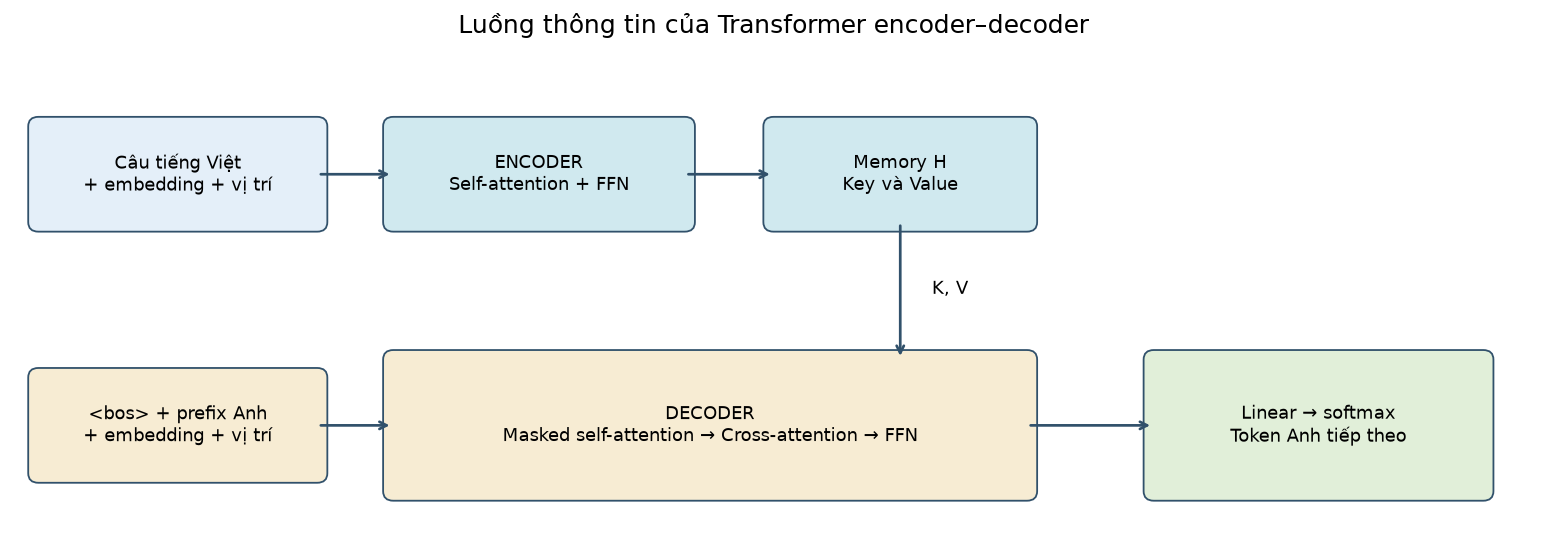

In [4]:
# Phụ trách: huy26ms23411@fsb.edu.vn | Vẽ luồng encoder decoder ở mức kiến trúc
# Đây là sơ đồ giải thích, không phải forward của mạng hoặc trọng số attention thật.
# box/arrow chỉ vẽ hình; thay kích thước hộp không thay d_model hay số head.
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(12, 4.3))
ax.set_xlim(0, 12); ax.set_ylim(0, 4); ax.axis('off')
def box(x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.08',
                 facecolor=color,edgecolor='#31516b'))
    ax.text(x+w/2,y+h/2,text,ha='center',va='center',fontsize=10)
def arrow(a,b):
    ax.annotate('',xy=b,xytext=a,arrowprops=dict(arrowstyle='->',lw=1.5,color='#31516b'))
# Nhánh trên: câu Việt -> embedding cộng vị trí -> encoder -> memory.
# Chữ Key/Value trong hộp là vai trò; trong mạng thật memory còn qua các phép chiếu học được.
box(.2,2.6,2.2,.8,'Câu tiếng Việt\n+ embedding + vị trí','#e4eff9')
box(3.0,2.6,2.3,.8,'ENCODER\nSelf-attention + FFN','#d0e9ef')
box(6.0,2.6,2.0,.8,'Memory H\nKey và Value','#d0e9ef')
# Nhánh dưới: <bos> và prefix Anh -> decoder; cross-attention truy xuất memory.
# Huấn luyện dùng prefix tham chiếu dịch phải; suy luận dùng prefix đã sinh.
box(.2,.5,2.2,.8,'<bos> + prefix Anh\n+ embedding + vị trí','#f7ecd3')
box(3.0,.35,5.0,1.1,'DECODER\nMasked self-attention → Cross-attention → FFN','#f7ecd3')
box(9.0,.35,2.6,1.1,'Linear → softmax\nToken Anh tiếp theo','#e1efd9')
# Mũi tên từ memory xuống decoder biểu diễn đường K,V; query đến từ decoder.
# Linear tạo logits vocabulary đích, softmax tạo xác suất; sơ đồ chỉ vẽ một bước.
# Vòng loss/backward/cập nhật và vòng nối token khi sinh được thực hiện ở phần B.
arrow((2.4,3),(3,3)); arrow((5.3,3),(6,3)); arrow((7,2.6),(7,1.45))
arrow((2.4,.9),(3,.9)); arrow((8,.9),(9,.9))
ax.text(7.25,2,'K, V',fontsize=10)
ax.set_title('Luồng thông tin của Transformer encoder–decoder',fontsize=14,pad=12)
plt.tight_layout(); plt.show()

## 5. Phần A: embedding và positional encoding

ID chỉ chọn một hàng trong bảng embedding $E$. Với token ở vị trí $p$:

$$X_p=\sqrt{d_{model}}E[token_p]+PE_p$$
$$PE(p,2i)=\sin\left(p/10000^{2i/d_{model}}\right),\quad
PE(p,2i+1)=\cos\left(p/10000^{2i/d_{model}}\right).$$

Embedding cho biết “token nào”; PE bổ sung “ở vị trí nào”. Hai vector được **cộng**, nên số chiều vẫn là 4. Không gán sẵn một chiều mang nghĩa “thạc sĩ” hoặc “công nghệ”; ý nghĩa hữu ích chỉ có thể hình thành qua học.

In [5]:
rng = np.random.default_rng(SEED)
D = 4

def positional_encoding(length, d):
    assert d % 2 == 0
    positions = np.arange(length)[:, None]
    frequencies = np.exp(np.arange(0,d,2) * (-np.log(10000.0)/d))
    pe = np.zeros((length,d))
    pe[:,0::2] = np.sin(positions * frequencies)
    pe[:,1::2] = np.cos(positions * frequencies)
    return pe

E_src = rng.normal(0,.2,(len(src_itos),D))
E_tgt = rng.normal(0,.2,(len(tgt_itos),D))
X = np.sqrt(D)*E_src[source_ids] + positional_encoding(S,D)
Y = np.sqrt(D)*E_tgt[decoder_ids] + positional_encoding(T,D)
table(['Token','Embedding','PE','Vector X'],
      [(src_tokens[i], np.round(E_src[source_ids[i]],3),
        np.round(positional_encoding(S,D)[i],3),np.round(X[i],3)) for i in range(3)])
print('X nguồn:', X.shape, '| Y decoder:', Y.shape)

Token,Embedding,PE,Vector X
tôi,[ 0.074 -0.192 0.176 -0.01 ],[0. 1. 0. 1.],[0.148 0.616 0.351 0.98 ]
đang,[-0.037 -0.136 0.245 -0.031],[0.841 0.54 0.01 1. ],[0.768 0.268 0.499 0.938]
học,[-0.086 -0.07 0.106 0.073],[ 0.909 -0.416 0.02 1. ],[ 0.738 -0.557 0.233 1.146]


X nguồn: (10, 4) | Y decoder: (10, 4)


## 6. Encoder self-attention: Q, K, V → scores → softmax → tổng hợp

$$Q=XW_Q,\quad K=XW_K,\quad V=XW_V$$
$$S=\frac{QK^\top}{\sqrt{d_k}},\quad A=\operatorname{softmax}_{key}(S),\quad Z=AV.$$

Hàng $i$ là query đang xử lý, cột $j$ là key được tham chiếu. Với một head ở phần A, $d_k=4$ nên chia dot product cho 2. Đây là **scaled dot product**, khác cosine similarity. Softmax tính theo từng hàng; tổng hàng bằng 1, tổng cột không bắt buộc bằng 1.

Ta trừ max trước khi tính exp để ổn định số. $Z_i$ là tổng có trọng số của các Value, chưa phải một từ tiếng Anh.

In [6]:
def softmax_np(scores):
    shifted = scores - scores.max(axis=-1,keepdims=True)
    exp_scores = np.exp(shifted)
    return exp_scores / exp_scores.sum(axis=-1,keepdims=True)

def weights(d):
    return [rng.normal(0,1/np.sqrt(d),(d,d)) for _ in range(4)]

def attention_np(query_input, key_input, value_input, W, blocked=None):
    wq,wk,wv,wo = W
    q,k,v = query_input@wq, key_input@wk, value_input@wv
    scores = q@k.T / np.sqrt(k.shape[-1])
    if blocked is not None:
        scores = np.where(blocked,-np.inf,scores)
    a = softmax_np(scores)
    return (a@v)@wo, dict(Q=q,K=k,V=v,scores=scores,A=a,Z=a@v)

W_enc = weights(D)
enc_attn_out, enc = attention_np(X,X,X,W_enc)
i = src_words.index('học')
print('Query của token học:',enc['Q'][i])
print('Key của token thạc:',enc['K'][src_words.index('thạc')])
print('Điểm học → thạc:',enc['scores'][i,src_words.index('thạc')])
print('Trọng số hàng học:',enc['A'][i])
contributions = enc['A'][i,:,None] * enc['V']
table(['Key nguồn','Trọng số','Value chiều 0','Đóng góp chiều 0'],
      [(w,f"{enc['A'][i,j]:.4f}", f"{enc['V'][j,0]:.4f}",
        f"{contributions[j,0]:.4f}") for j,w in enumerate(src_tokens)])
print('Tổng vector đóng góp:',contributions.sum(axis=0))
assert np.allclose(contributions.sum(axis=0),enc['Z'][i])
assert np.allclose(enc['A'].sum(axis=1),1)

Query của token học: [-0.5144  0.2494  0.4547 -0.3901]
Key của token thạc: [-0.5159 -0.6222 -1.3529 -0.3412]
Điểm học → thạc: -0.18588704865569686
Trọng số hàng học: [0.1142 0.1116 0.0889 0.0942 0.0737 0.0854 0.117  0.1206 0.0966 0.0977]


Key nguồn,Trọng số,Value chiều 0,Đóng góp chiều 0
tôi,0.1142,0.5304,0.0606
đang,0.1116,0.4730,0.0528
học,0.0889,0.5164,0.0459
thạc,0.0942,-0.0357,-0.0034
sĩ,0.0737,0.3032,0.0224
công,0.0854,0.6164,0.0527
nghệ,0.1170,0.9121,0.1067
thông,0.1206,0.6939,0.0837
tin,0.0966,0.7595,0.0734
<eos>,0.0977,0.2085,0.0204


Tổng vector đóng góp: [ 0.5151  0.1096  0.0399 -0.1294]


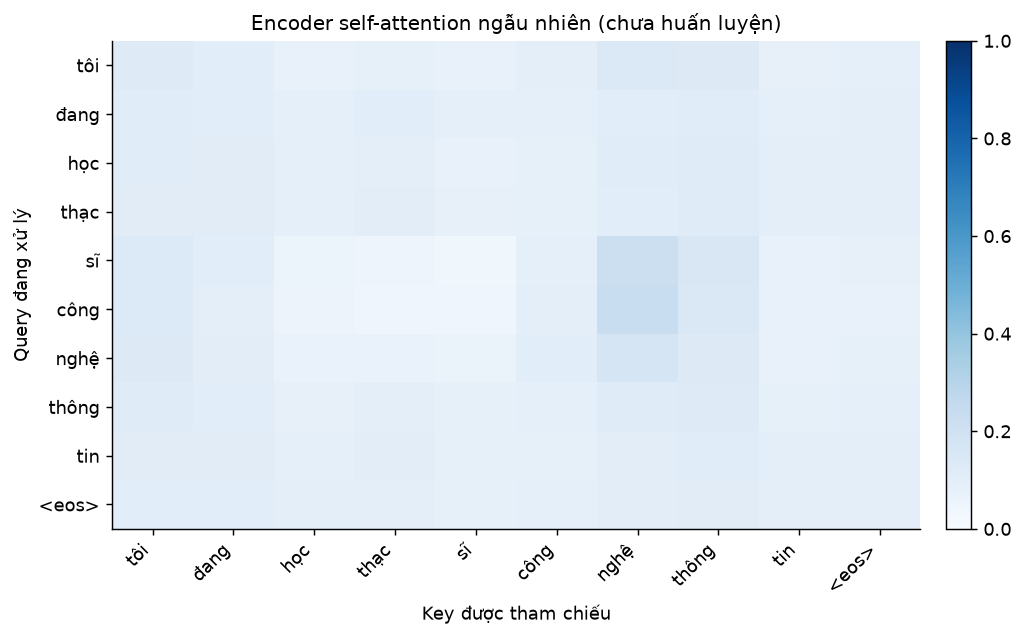

In [7]:
def heatmap(matrix, xs, ys, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(8,5))
    im=ax.imshow(matrix,cmap='Blues',vmin=0,vmax=1,aspect='auto')
    ax.set_xticks(range(len(xs)),xs,rotation=45,ha='right')
    ax.set_yticks(range(len(ys)),ys)
    ax.set_title(title,fontsize=11)
    ax.set_xlabel('Key được tham chiếu'); ax.set_ylabel('Query đang xử lý')
    plt.colorbar(im,ax=ax,fraction=.035,pad=.03)
    return ax

heatmap(enc['A'],src_tokens,src_tokens,'Encoder self-attention ngẫu nhiên (chưa huấn luyện)')
plt.tight_layout(); plt.show()

### 6.1. Hoàn thành encoder: residual, LayerNorm và FFN

$$U=\operatorname{LN}(X+ZW_O),\qquad H=\operatorname{LN}(U+\operatorname{FFN}(U))$$
$$\operatorname{FFN}(U)=\operatorname{ReLU}(UW_1+b_1)W_2+b_2.$$

Residual cộng luồng đầu vào với phép biến đổi; LayerNorm chuẩn hóa trên **chiều đặc trưng của từng token**, không chuẩn hóa trên toàn câu; FFN áp dụng cùng mạng lên từng vị trí. Phần tính tay đặt gamma=1, beta=0; phần B dùng gamma/beta học được. $H$ là encoder memory có shape $10\times4$.

In [8]:
def layernorm_np(x,eps=1e-5):
    return (x-x.mean(axis=-1,keepdims=True))/np.sqrt(x.var(axis=-1,keepdims=True)+eps)

def new_ffn(d):
    return (rng.normal(0,1/np.sqrt(d),(d,2*d)),np.zeros(2*d),
            rng.normal(0,1/np.sqrt(2*d),(2*d,d)),np.zeros(d))

def ffn_np(x,params):
    w1,b1,w2,b2=params
    return np.maximum(0,x@w1+b1)@w2+b2

encoder_u = layernorm_np(X+enc_attn_out)
H = layernorm_np(encoder_u+ffn_np(encoder_u,new_ffn(D)))
print('Memory H:',H.shape)
print('Memory tại học:',H[i])

Memory H: (10, 4)
Memory tại học: [-0.5224 -1.0252 -0.086   1.6336]


## 7. Decoder masked self-attention

Q/K/V đều đến từ luồng decoder. Ma trận `blocked[i,j]=True` nếu $j>i$. Ta gán điểm ở vị trí tương lai thành $-\infty$ **trước softmax**, nên trọng số tương ứng bằng 0. Diagonal vẫn được phép vì decoder input đã được dịch phải.

Ví dụ vị trí 1 nhận `i` để dự đoán `am`: nó được nhìn `<bos>, i`, nhưng không nhìn `am` ở input vị trí 2. **Dịch phải và causal mask đều cần thiết.** Khi huấn luyện, mọi vị trí có thể xử lý song song; khi suy luận, phải sinh tuần tự.

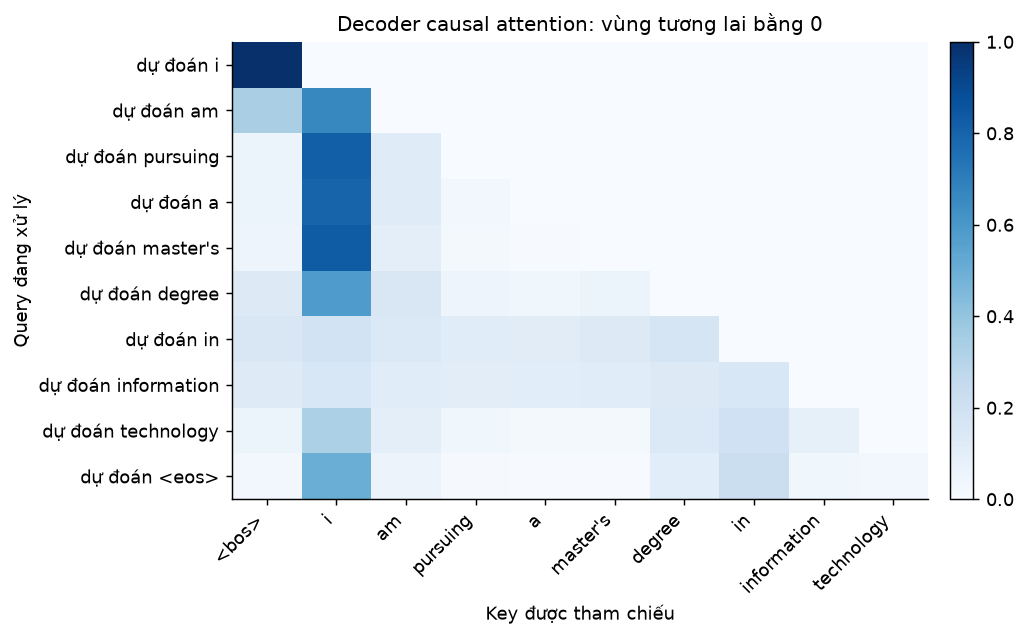

In [9]:
future_mask = np.triu(np.ones((T,T),dtype=bool),k=1)
dec_self_out, dec_self = attention_np(Y,Y,Y,weights(D),future_mask)
D1 = layernorm_np(Y+dec_self_out)
assert np.allclose(dec_self['A'][future_mask],0)
assert np.allclose(dec_self['A'].sum(axis=-1),1)
heatmap(dec_self['A'],dec_tokens,['dự đoán '+w for w in label_tokens],
        'Decoder causal attention: vùng tương lai bằng 0')
plt.tight_layout(); plt.show()

## 8. Cross-attention: cầu nối câu Việt và câu Anh

$$Q_c=D_1W_{Qc},\quad K_c=HW_{Kc},\quad V_c=HW_{Vc}$$
$$A_c=\operatorname{softmax}(Q_cK_c^\top/\sqrt{d_k}),\qquad C=A_cV_cW_{Oc}.$$

Query đến từ decoder; Key và Value từ encoder memory. Decoder có thể tham chiếu **toàn bộ nguồn**, nên không dùng causal mask theo nguồn trong bài dịch toàn câu. Nếu có padding thì cần mask các key `<pad>`.

Trong ví dụ này số hàng đích và cột nguồn tình cờ đều là 10; hai chiều vẫn có ý nghĩa khác nhau. Các hàng được ghi **“dự đoán …”** để chỉ nhãn ở vị trí đó, không nhầm với token decoder input. Ô đậm trước huấn luyện không thể được giải thích là mô hình đã biết căn chỉnh từ.

Q cross: (10, 4) | K/V cross: (10, 4)
Attention cross: (10, 10) | Decoder output: (10, 4)


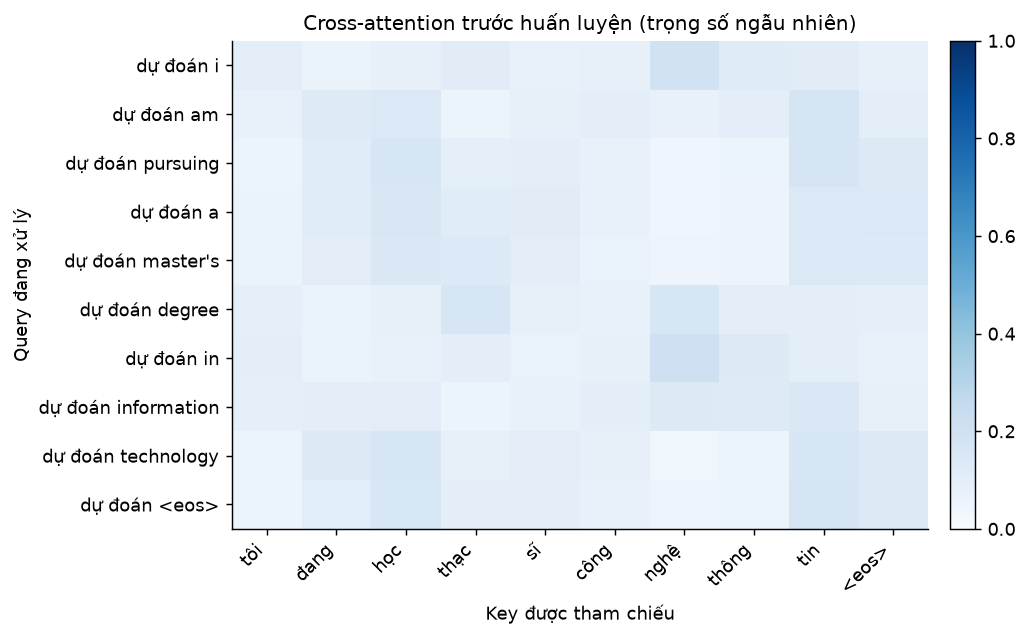

In [10]:
cross_out, cross = attention_np(D1,H,H,weights(D))
D2 = layernorm_np(D1+cross_out)
D_out = layernorm_np(D2+ffn_np(D2,new_ffn(D)))
print('Q cross:',cross['Q'].shape,'| K/V cross:',cross['K'].shape)
print('Attention cross:',cross['A'].shape,'| Decoder output:',D_out.shape)
heatmap(cross['A'],src_tokens,['dự đoán '+w for w in label_tokens],
        'Cross-attention trước huấn luyện (trọng số ngẫu nhiên)')
plt.tight_layout(); plt.show()

## 9. Từ vector decoder đến xác suất từ vựng và loss

$$logits = D_{out}W_{vocab} + b_{vocab}, \quad P = \operatorname{softmax}_{vocab}(logits)$$
$$\mathcal L = -\frac{1}{T}\sum_{t=1}^{T}\log P_{t, y_t}.$$

### 9.1. Từ vector Decoder đến xác suất và hàm mất mát (Loss)
1. **Output Projection:** Biến đổi biểu diễn vector ẩn của Decoder $D_{out} \in \mathbb{R}^{T \times D}$ thành ma trận điểm số $logits \in \mathbb{R}^{T \times |V_{tgt}|}$ thông qua ma trận trọng số $W_{vocab} \in \mathbb{R}^{D \times |V_{tgt}|}$. Phép chiếu này mở rộng không gian đặc trưng ẩn ($D=4$) sang không gian kích thước từ vựng đích ($|V_{tgt}|=13$).
2. **Softmax chuyển Logits thành xác suất:**
   $$P_{t, v} = \frac{e^{logits_{t, v}}}{\sum_{v'=1}^{|V_{tgt}|} e^{logits_{t, v'}}}$$
   Hàm Softmax chuyển các giá trị thực không giới hạn trong logits về phân phối xác suất hợp lệ: $P_{t, v} \in [0, 1]$ và tổng xác suất trên toàn bộ từ vựng tại mỗi vị trí $t$ luôn bằng đúng $1.0$ ($\sum_v P_{t, v} = 1$).
3. **Cross-Entropy / Negative Log-Likelihood (NLL):** Đo mức độ bất ngờ (surprisal) và sai lệch giữa phân phối dự đoán $P$ của mô hình với nhãn đúng $y_t$. Tại mỗi vị trí $t$, hàm loss trích xuất đúng $-\log P_{t, y_t}$. Xác suất gán cho nhãn đúng càng tiệm cận 0 thì loss càng tiến tới vô cùng (phạt nặng).

> **Phân biệt hai loại Softmax:**
> - **Softmax trong Attention:** Chuẩn hóa theo chiều dài chuỗi nguồn/đích (key positions $S$ hoặc $T$), xác định tỷ trọng thông tin cần tập trung giữa các token.
> - **Softmax ở Output:** Chuẩn hóa trên toàn bộ không gian từ điển đích $|V_{tgt}|$, xác định phân phối xác suất để lựa chọn từ tiếp theo.
> *Lưu ý quan trọng:* Không được lấy token có attention lớn nhất làm trực tiếp từ tiếng Anh đầu ra; dự đoán từ bắt buộc phải thông qua Output Projection và Softmax từ điển.

### 9.2. Trả lời câu hỏi trọng tâm
- **Logits khác xác suất thế nào?**
  + *Logits:* Là các giá trị điểm số thực chưa chuẩn hóa (unnormalized scores), thuộc khoảng $(-\infty, +\infty)$, sinh ra trực tiếp từ phép nhân tuyến tính $D_{out}W_{vocab}$. Logits chưa thể hiện tỷ lệ phần trăm tin cậy do chưa được chuẩn hóa.
  + *Xác suất:* Là giá trị sau khi logits đi qua hàm Softmax, bị chặn nghiêm ngặt trong đoạn $[0, 1]$ và có tổng trên toàn bộ từ điển đích bằng đúng $1.0$, phản ánh mức độ tự tin khách quan của mô hình cho từng token.
- **Loss được tính dựa trên đầu ra và nhãn nào?**
  + *Đầu ra:* Ma trận Logits (hoặc phân phối xác suất $P$) từ Decoder tại từng bước dự đoán $t \in [1, T]$ với kích thước $(10, 13)$.
  + *Nhãn:* Token mục tiêu thực tế tương ứng $y_t \in \text{label\_ids}$ (gồm 9 từ vựng tiếng Anh và token kết thúc `<eos>`).
  + *Giá trị loss:* $\mathcal{L} = -\frac{1}{T}\sum_{t=1}^T \log P_{t, y_t}$, phạt trực tiếp nếu xác suất của từ đúng $y_t$ bị dự đoán thấp.

In [11]:
# ==============================================================================
# MỤC 9: HIỆN THỰC NUMPY TỪ BIỂU DIỄN DECODER ĐẾN XÁC SUẤT VÀ LOSS
# ==============================================================================

# 1. Khởi tạo ma trận Output Projection W_vocab:
#    Ánh xạ từ không gian ẩn của Decoder (D = 4) sang không gian từ vựng đích (|V_tgt| = 13).
#    Khởi tạo chuẩn hóa với độ lệch chuẩn 1/sqrt(D) giúp ổn định phương sai ban đầu.
W_vocab = rng.normal(0, 1 / np.sqrt(D), (D, len(tgt_itos)))

# 2. Tính Logits (điểm số chưa chuẩn hóa):
#    Shape: (T, D) @ (D, |V_tgt|) -> (T, |V_tgt|) = (10, 13)
#    Mỗi hàng đại diện cho 10 vị trí dự đoán, mỗi cột là điểm số cho 1 trong 13 token đích.
logits_np = D_out @ W_vocab

# 3. Chuyển Logits thành phân phối xác suất bằng hàm Softmax theo trục từ vựng (axis=-1):
#    Shape giữ nguyên (10, 13), giá trị mỗi phần tử nằm trong [0, 1] và tổng mỗi hàng bằng 1.0.
P_np = softmax_np(logits_np)

# 4. Tính Negative Log-Likelihood (NLL / Cross-Entropy Loss):
#    np.arange(T) tạo chỉ số hàng 0..9, label_ids trích đúng cột chứa nhãn thực tế.
#    Công thức tại mỗi vị trí t: nll_np[t] = -ln(P[t, label_ids[t]])
nll_np = -np.log(P_np[np.arange(T), label_ids])

# 5. Quan sát 5 ứng viên có xác suất cao nhất tại vị trí dự đoán đầu tiên (t=0):
first_top = np.argsort(-P_np[0])[:5]
table(['Ứng viên ở vị trí đầu', 'Logit', 'Xác suất'],
      [(tgt_itos[j], f'{logits_np[0, j]:.4f}', f'{P_np[0, j]:.4f}') for j in first_top])

print('Nhãn đầu:', label_tokens[0], '| p:', P_np[0, label_ids[0]])
print('Loss vị trí đầu:', nll_np[0])
print('Loss trung bình phần A:', nll_np.mean())

# 6. Kiểm tra tính toàn vẹn (Asserts):
#    - P_np phải có đúng kích thước (T, |V_tgt|) = (10, 13).
#    - Tổng xác suất theo hàng (trục từ điển) phải xấp xỉ chính xác bằng 1.0.
assert P_np.shape == (T, len(tgt_itos))
assert np.allclose(P_np.sum(axis=1), 1)

Ứng viên ở vị trí đầu,Logit,Xác suất
technology,1.3792,0.2311
information,1.3221,0.2182
degree,0.7379,0.1217
a,0.3372,0.0815
pursuing,0.2198,0.0725


Nhãn đầu: i | p: 0.060025540582393545
Loss vị trí đầu: 2.8129851309612954
Loss trung bình phần A: 2.9332873309041814


## 10. Tổng hợp kích thước và các kiểm tra phần A

### 10.1. Bảng tổng hợp kích thước các đại lượng (Tensor Shapes)

| Đại lượng | Shape | Ý nghĩa toán học & vai trò |
|---|---|---|
| Source IDs | (10,) | 9 âm tiết câu tiếng Việt + token kết thúc `<eos>` |
| Decoder input / nhãn | (10,) | Prefix dịch phải (`<bos>` + 9 từ đầu) / Ground truth (9 từ đầu + `<eos>`) |
| Embedding nguồn X | (10, 4) | Số vị trí nguồn $S=10$ × chiều đặc trưng ẩn $D=4$ |
| Encoder attention | (10, 10) | Query nguồn × Key nguồn ($S \times S$); giao tiếp hai chiều không mask |
| Decoder self-attention | (10, 10) | Query đích × Key đích ($T \times T$); áp dụng Causal Mask triệt tiêu tương lai |
| Cross-attention | (10, 10) | Query đích × Key nguồn ($T \times S$); cầu nối thông tin hai ngôn ngữ |
| Logits | (10, 13) | Vị trí đích $T=10$ × không gian từ vựng đích $|V_{tgt}|=13$ |

> **Lưu ý cốt lõi về kích thước chuỗi:**
> Việc câu nguồn và câu đích trong ví dụ này đều có độ dài bằng nhau ($S = T = 10$) chỉ là đặc điểm ngẫu nhiên của câu văn được chọn. Trong kiến trúc Transformer tổng quát, độ dài câu nguồn $S$ và câu đích $T$ hoàn toàn độc lập ($S \neq T$). Khi đó ma trận Cross-Attention luôn có kích thước chuẩn là $(T, S)$, phản ánh $T$ truy vấn từ Decoder tìm kiếm trên $S$ trạng thái bộ nhớ Encoder.

### 10.2. Mục đích và ý nghĩa các phép kiểm tra `assert` trong phần A
- `assert len(tgt_words) == 9 and len(tgt_itos) == 13`: Đảm bảo từ vựng đích được xây dựng chính xác, bao gồm 4 token đặc biệt (`<pad>`, `<unk>`, `<bos>`, `<eos>`) và 9 từ vựng tiếng Anh không trùng lặp.
- `assert H.shape == (S, D) and cross['A'].shape == (T, S)`: Kiểm chứng Encoder Memory $H$ bảo toàn đúng kích thước $(10, 4)$ và ma trận Cross-Attention liên kết chuẩn xác giữa $T$ vị trí đích và $S$ vị trí nguồn.
- `assert np.allclose(cross['A'].sum(axis=1), 1)`: Khẳng định tính chất tiên đề xác suất của Softmax trong Cross-Attention: tại mỗi bước dịch, tổng trọng số tập trung vào toàn bộ câu nguồn luôn bằng 1.0.
- `assert np.all(np.isfinite(D_out))`: Đảm bảo độ ổn định số học (numerical stability); đầu ra Decoder không bị tràn số, phân kỳ hoặc sinh ra NaN/Inf sau các tầng Residual, LayerNorm và FFN.
- `assert np.allclose(softmax_np(test_scores), dec_self['A'])`: Kiểm tra tính bất biến của Causal Mask. Dù điểm số tại các vị trí tương lai bị gán giá trị nhiễu cực lớn ($10^9$) trước khi mask bằng $-\infty$, hàm Softmax vẫn triệt tiêu hoàn toàn thành xác suất 0.0, chứng minh không hề xảy ra rò rỉ dữ liệu tương lai (data leakage).

In [12]:
# ==============================================================================
# MỤC 10: KIỂM CHỨNG TÍNH TOÀN VẸN CÁC ĐẠI LƯỢNG VÀ BẤT BIẾN TOÁN HỌC (PHẦN A)
# ==============================================================================

# 1. Kiểm tra độ dài danh sách từ và kích thước từ vựng đích:
#    9 từ nội dung ('i', 'am', 'pursuing', 'a', "master's", 'degree', 'in', 'information', 'technology')
#    kết hợp 4 token đặc biệt (<pad>, <unk>, <bos>, <eos>) tạo thành đúng 13 token trong từ điển.
assert len(tgt_words) == 9 and len(tgt_itos) == 13

# 2. Kiểm tra shape biểu diễn bộ nhớ Encoder H (S, D) và ma trận Cross-Attention (T, S):
#    H có kích thước (10, 4) và trọng số Cross-Attention nối T vị trí đích với S vị trí nguồn (10, 10).
assert H.shape == (S, D) and cross['A'].shape == (T, S)

# 3. Kiểm tra tính hợp lệ của phân phối xác suất trong Cross-Attention:
#    Tổng trọng số chú ý của mỗi Query đích trên toàn bộ câu nguồn (axis=1) phải luôn bằng 1.0.
assert np.allclose(cross['A'].sum(axis=1), 1)

# 4. Kiểm tra tính ổn định số học (numerical stability):
#    Biểu diễn cuối của Decoder D_out không được chứa giá trị vô hạn (inf) hoặc giá trị không xác định (NaN).
assert np.all(np.isfinite(D_out))

# 5. Kiểm tra tính bất biến và độ an toàn của Causal Mask:
#    Dù điểm số ban đầu tại vùng tương lai có bị nhiễu hay mang giá trị cực lớn (1e9),
#    khi mask bằng -np.inf thì hàm Softmax phải biến chúng thành đúng 0.0,
#    kết quả xác suất sau Softmax phải hoàn toàn trùng khớp với ma trận dec_self['A'].
test_scores = dec_self['scores'].copy()
test_scores[future_mask] = 1e9
test_scores[future_mask] = -np.inf
assert np.allclose(softmax_np(test_scores), dec_self['A'])

print('Phần A: kích thước, softmax, tổng Value và causal mask đều đúng.')

Phần A: kích thước, softmax, tổng Value và causal mask đều đúng.


## 11. Phần B: Transformer có tham số học được bằng PyTorch

Phần này xây dựng **mô hình học máy hoàn chỉnh** với các tham số có thể tối ưu hóa qua lan truyền ngược (Backpropagation), tách biệt hoàn toàn với các phép tính minh họa trên ma trận tĩnh NumPy ở Phần A.

### 11.1. Cấu hình siêu tham số mô hình
- `d_model = 32`: Kích thước không gian biểu diễn ẩn (embedding dimension và hidden size xuyên suốt mô hình).
- `n_heads = 4`: Số lượng head trong cơ chế Multi-Head Attention. Mỗi head hoạt động trên không gian con có số chiều $d_k = d_v = d_{model} / n_{heads} = 32 / 4 = 8$.
- `d_ff = 64`: Kích thước tầng ẩn của mạng truyền thẳng Feed-Forward Network ($32 \to 64 \to 32$), sử dụng hàm kích hoạt ReLU.
- `max_len = 64`: Giới hạn độ dài chuỗi tối đa được bảng Positional Encoding hình sin hỗ trợ.
- Số block: Sử dụng **1 Encoder Block** và **1 Decoder Block** — thiết kế tinh gọn, vừa vặn để minh họa khả năng ghi nhớ cặp câu mà không gây dư thừa tham số.

$$head_i = Attention(Q_i, K_i, V_i), \quad MultiHead = Concat(head_1, \ldots, head_4)W_O.$$

### 11.2. Vai trò của các thành phần kiến trúc
1. **EncoderBlock:**
   - Thực hiện Multi-Head Self-Attention cho chuỗi câu nguồn tiếng Việt (bidirectional), cho phép các âm tiết tương tác tự do không hạn chế vị trí.
   - Cấu trúc **Post-LN**: $U = \operatorname{LN}(x + \text{SelfAttn}(x))$, tiếp nối bởi $H = \operatorname{LN}(U + \text{FFN}(U))$.
   - Tạo ra bộ nhớ ngữ cảnh `memory` đại diện cho toàn bộ thông tin câu nguồn.
2. **DecoderBlock:**
   - *Sublayer 1 (Masked Self-Attention):* Xử lý chuỗi tiền tố đích tiếng Anh; dùng Causal Mask để đảm bảo bước $t$ không nhìn thấy các token ở tương lai $> t$.
   - *Sublayer 2 (Cross-Attention):* Query lấy từ biểu diễn của Decoder, còn Key và Value lấy từ `memory` của Encoder. Đây là cơ chế cốt lõi kết nối thông tin giữa hai ngôn ngữ.
   - *Sublayer 3 (Feed-Forward Network):* Biến đổi phi tuyến đặc trưng tại từng vị trí độc lập.
3. **Lớp mô hình `TinyTranslator`:**
   - Quản lý 2 bảng Embedding học được cho câu nguồn (`src_emb`) và câu đích (`tgt_emb`).
   - Positional Encoding (hình sin): Cố định qua `register_buffer`, tự chuyển thiết bị cùng mô hình nhưng không nhận gradient.
   - Output Projection (`proj`): Biến đổi vector ẩn cuối cùng từ chiều $d_{model}=32$ sang logits trên không gian từ vựng đích $|V_{tgt}|=13$.
   - `dropout = 0.0`: Bài thực hành tập trung vào bài toán ghi nhớ (memorization) một cặp câu, do đó tắt hoàn toàn dropout để quá trình tái lập kết quả đạt tính tất định cao nhất.

In [13]:
# ==============================================================================
# MỤC 11: CẤU HÌNH THỰC NGHIỆM VÀ KHỞI TẠO TENSOR PYTORCH
# ==============================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# 1. Thiết lập hạt giống ngẫu nhiên (seed) để đảm bảo 100% khả năng tái lập kết quả:
torch.manual_seed(SEED)

# 2. Cố định 1 CPU thread nhằm giảm thiểu chi phí chuyển ngữ cảnh (overhead) cho mô hình nhỏ:
torch.set_num_threads(1)

# 3. Thiết bị thực thi: Cố định chạy trên CPU để đảm bảo tính nhất quán giữa các môi trường:
DEVICE = torch.device('cpu')

# 4. Cấu hình siêu tham số mô hình (Hyperparameters):
#    - d_model = 32: Kích thước vector biểu diễn ẩn
#    - n_heads = 4: Số lượng attention head (mỗi head d_k = 8)
#    - d_ff = 64: Kích thước tầng ẩn của FFN
#    - max_len = 64: Độ dài chuỗi tối đa được mã hóa vị trí
CONFIG = dict(d_model=32, n_heads=4, d_ff=64, max_len=64)

# 5. Số bước tối ưu hóa (STEPS) và tốc độ học (Learning Rate):
STEPS, LR = 500, 0.01

# 6. Chuẩn bị tensor đầu vào với batch dimension (batch_size = 1):
#    Định dạng đầu vào chuẩn của PyTorch yêu cầu kích thước (batch_size, sequence_length).
#    Phương thức .unsqueeze(0) biến tensor 1D (10,) thành tensor 2D (1, 10).
#    - src: Token IDs của câu nguồn tiếng Việt + <eos>
#    - dec: Token IDs tiền tố dịch phải của câu đích bắt đầu bằng <bos> (Teacher Forcing input)
#    - labels: Token IDs đích thực tế cần dự đoán kết thúc bằng <eos> (Ground truth target)
src = torch.tensor(source_ids, dtype=torch.long, device=DEVICE).unsqueeze(0)
dec = torch.tensor(decoder_ids, dtype=torch.long, device=DEVICE).unsqueeze(0)
labels = torch.tensor(label_ids, dtype=torch.long, device=DEVICE).unsqueeze(0)

print('PyTorch:', torch.__version__, '| Thiết bị:', DEVICE)
print('Cấu hình:', CONFIG, '| Số bước:', STEPS, '| LR:', LR)

PyTorch: 2.14.1+cpu | Thiết bị: cpu
Cấu hình: {'d_model': 32, 'n_heads': 4, 'd_ff': 64, 'max_len': 64} | Số bước: 500 | LR: 0.01


In [14]:
# ==============================================================================
# MỤC 11: HIỆN THỰC KIẾN TRÚC TRANSFORMER BẰNG PYTORCH
# ==============================================================================

class EncoderBlock(nn.Module):
    """
    Khối Encoder Transformer gồm:
    - Multi-Head Self-Attention (hai chiều, không che tương lai).
    - Kết nối tắt Residual và chuẩn hóa Post-LayerNorm.
    - Mạng truyền thẳng FFN (Linear -> ReLU -> Linear) kèm Residual và LayerNorm.
    """
    def __init__(self, d, h, ff):
        super().__init__()
        # batch_first=True nhận tensor dạng (batch_size, seq_len, d_model)
        self.attn = nn.MultiheadAttention(d, h, dropout=0.0, batch_first=True)
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d, ff), nn.ReLU(), nn.Linear(ff, d))

    def forward(self, x, pad):
        # Self-attention: Q, K, V cùng đến từ biểu diễn x.
        # key_padding_mask=pad: True tại các vị trí <pad> để loại bỏ khỏi chú ý.
        # average_attn_weights=False: Trả về ma trận trọng số riêng biệt của từng head (h, S, S).
        a, w = self.attn(x, x, x, key_padding_mask=pad, need_weights=True,
                         average_attn_weights=False)
        # Cấu trúc Post-LN: Residual add trước, sau đó qua LayerNorm
        x = self.norm1(x + a)
        return self.norm2(x + self.ff(x)), w


class DecoderBlock(nn.Module):
    """
    Khối Decoder Transformer gồm:
    - Masked Multi-Head Self-Attention: Áp dụng Causal Mask ngăn nhìn trước token tương lai.
    - Multi-Head Cross-Attention: Query từ Decoder, Key và Value từ Encoder memory.
    - Mạng truyền thẳng FFN kèm các tầng Residual và Post-LayerNorm.
    """
    def __init__(self, d, h, ff):
        super().__init__()
        self.self_attn = nn.MultiheadAttention(d, h, dropout=0.0, batch_first=True)
        self.cross_attn = nn.MultiheadAttention(d, h, dropout=0.0, batch_first=True)
        self.norm1, self.norm2, self.norm3 = [nn.LayerNorm(d) for _ in range(3)]
        self.ff = nn.Sequential(nn.Linear(d, ff), nn.ReLU(), nn.Linear(ff, d))

    def forward(self, x, memory, causal, tgt_pad, src_pad):
        # 1. Masked Self-Attention:
        #    attn_mask=causal: Che các vị trí tương lai j > i bằng -inf.
        #    key_padding_mask=tgt_pad: Che các token đệm trong chuỗi đích.
        a, ws = self.self_attn(x, x, x, attn_mask=causal, key_padding_mask=tgt_pad,
                               need_weights=True, average_attn_weights=False)
        x = self.norm1(x + a)

        # 2. Cross-Attention:
        #    Query từ biểu diễn Decoder (x), Key và Value từ bộ nhớ Encoder (memory).
        #    key_padding_mask=src_pad: Che các token đệm trong câu nguồn tiếng Việt.
        c, wc = self.cross_attn(x, memory, memory, key_padding_mask=src_pad,
                                need_weights=True, average_attn_weights=False)
        x = self.norm2(x + c)

        # 3. Feed-Forward Network kết hợp Residual và LayerNorm cuối cùng
        return self.norm3(x + self.ff(x)), ws, wc


class TinyTranslator(nn.Module):
    """
    Mô hình Seq2Seq Transformer hoàn chỉnh:
    - Embeddings: Chuyển ID thành vector d_model cho cả câu nguồn và đích.
    - Positional Encoding hình sin: Cố định thông qua register_buffer.
    - 1 Encoder Block và 1 Decoder Block.
    - Output Projection (nn.Linear): Biến vector Decoder (d_model) thành Logits từ vựng đích.
    """
    def __init__(self, src_size, tgt_size, d_model, n_heads, d_ff, max_len):
        super().__init__()
        assert d_model % n_heads == 0, "d_model phải chia hết cho số lượng head!"
        self.d = d_model
        self.src_emb = nn.Embedding(src_size, d_model, padding_idx=PAD)
        self.tgt_emb = nn.Embedding(tgt_size, d_model, padding_idx=PAD)

        # register_buffer: Lưu trữ tensor trong state_dict và theo thiết bị (device),
        # nhưng KHÔNG nhận gradient (requires_grad=False) vì là hàm hình sin cố định.
        self.register_buffer('pe', torch.tensor(positional_encoding(max_len, d_model), dtype=torch.float32))

        self.encoder = EncoderBlock(d_model, n_heads, d_ff)
        self.decoder = DecoderBlock(d_model, n_heads, d_ff)

        # Lớp Output Projection: Chiếu từ d_model (32) sang kích thước từ điển đích (tgt_size=13)
        self.proj = nn.Linear(d_model, tgt_size)

    def embed(self, ids, embedding):
        """Nhân hệ số căn bậc hai của d_model với embedding rồi cộng Positional Encoding"""
        if ids.shape[1] > self.pe.shape[0]:
            raise ValueError('Chuỗi dài hơn max_len; cần tăng cấu hình và huấn luyện lại.')
        return math.sqrt(self.d) * embedding(ids) + self.pe[:ids.shape[1]]

    def forward(self, source, prefix):
        # Tạo mask cho token PAD
        src_pad, tgt_pad = source.eq(PAD), prefix.eq(PAD)

        # 1. Mã hóa câu nguồn tiếng Việt qua Encoder
        memory, we = self.encoder(self.embed(source, self.src_emb), src_pad)

        # 2. Tạo Causal Mask tam giác trên (True ở các vị trí tương lai diagonal >= 1)
        n = prefix.shape[1]
        causal = torch.triu(torch.ones(n, n, dtype=torch.bool, device=prefix.device), diagonal=1)

        # 3. Giải mã tiền tố câu đích qua Decoder kết hợp Encoder memory
        out, ws, wc = self.decoder(self.embed(prefix, self.tgt_emb), memory, causal, tgt_pad, src_pad)

        # 4. Chiếu vector Decoder thành Logits từ vựng đích và trả kèm attention weights
        return self.proj(out), {'encoder': we, 'decoder': ws, 'cross': wc}


# Khởi tạo mô hình và chuyển sang thiết bị CPU
model = TinyTranslator(len(src_itos), len(tgt_itos), **CONFIG).to(DEVICE)
print('Tổng tham số học được:', sum(p.numel() for p in model.parameters()))
print('Input source/decoder:', tuple(src.shape), tuple(dec.shape))

Tổng tham số học được: 22637
Input source/decoder: (1, 10) (1, 10)


## 12. Huấn luyện bằng teacher forcing, cross-entropy và Adam

Quá trình huấn luyện tối ưu hóa các tham số của mô hình để ghi nhớ chính xác bản dịch của cặp câu mẫu thông qua cơ chế Teacher Forcing và thuật toán Adam.

### 12.1. Cơ chế Teacher Forcing
- **Nguyên lý hoạt động:** Tại mỗi bước dự đoán token thứ $t$, Decoder **không** sử dụng token do chính nó sinh ra ở bước $t-1$ (vốn có thể sai lệch, đặc biệt ở giai đoạn đầu), mà luôn nhận trực tiếp chuỗi token chuẩn xác của câu đích thực tế đã được **dịch phải một vị trí** (`prefix` = `decoder_ids` = `[<bos>, y_1, y_2, ..., y_{T-1}]`).
- **Ưu điểm vượt trội:** Nhờ kết hợp Causal Mask, toàn bộ quá trình tính toán qua tất cả các bước thời gian $t=1 \ldots T$ được ma trận hóa và thực hiện **song song hoàn toàn** trong một lượt forward duy nhất. Quá trình hội tụ diễn ra ổn định và nhanh chóng, không bị ảnh hưởng bởi lỗi tích lũy lan truyền (compounding error).

### 12.2. Vòng lặp cập nhật tham số (6 bước chuẩn)
Mỗi bước lặp tối ưu hóa tuân theo trình tự bất biến:
$$\text{zero\_grad} \longrightarrow \text{forward} \longrightarrow \text{loss} \longrightarrow \text{backward} \longrightarrow \text{clip} \longrightarrow \text{step}$$
1. `model.train()`: Đặt mô hình ở chế độ huấn luyện.
2. `optimizer.zero_grad(set_to_none=True)`: Xóa các gradient tích lũy từ bước trước đó. Tùy chọn `set_to_none=True` giải phóng trực tiếp vùng nhớ thay vì gán 0, giúp tăng tốc thực thi.
3. `forward`: Truyền `src` và `dec` qua mô hình để nhận ma trận `logits` có kích thước $(1, 10, 13)$.
4. `loss`: Hàm `F.cross_entropy` tính toán sai khác giữa `logits` thô và nhãn mục tiêu `labels` (`[y_1, \ldots, y_T, <eos>]`). Hàm này đã tích hợp sẵn phép biến đổi Log-Softmax và Negative Log-Likelihood với kỹ thuật số học Log-Sum-Exp ổn định chống tràn số. Tham số `ignore_index=PAD` đảm bảo các token đệm không gây ảnh hưởng đến hàm mất mát.
5. `loss.backward()`: Cơ chế Autograd của PyTorch tự động duyệt ngược đồ thị tính toán để tính đạo hàm riêng $\frac{\partial \mathcal{L}}{\partial \theta}$ cho từng tham số $\theta$ học được.
6. `nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)`: Giới hạn độ dài chuẩn vector gradient. Nếu $\|\mathbf{g}\|_2 > 1.0$, gradient sẽ được co tỷ lệ về đúng ngưỡng $1.0$.
7. `optimizer.step()`: Thuật toán Adam điều chỉnh các trọng số dựa trên gradient đã cắt tỉa và ước lượng moment động lượng bậc 1, bậc 2.

### 12.3. Trả lời các câu hỏi tự phản biện
- **Teacher forcing hoạt động ra sao?**
  + Decoder nhận toàn bộ chuỗi đích dịch phải làm đầu vào (`<bos>` + chuỗi token đích). Tại bước $t$, Decoder chỉ nhìn thấy các token quá khứ từ $1$ đến $t-1$ nhờ Causal Mask, và có nhiệm vụ dự đoán đúng token thứ $t$. Điều này biến bài toán sinh chuỗi tuần tự thành bài toán phân loại đa lớp song song tại mọi vị trí thời gian.
- **Gradient được tính và cập nhật theo trình tự nào?**
  + Trình tự chuẩn: `zero_grad` (xóa grad cũ) $\to$ `forward` (tính output) $\to$ `loss` (tính lỗi so với nhãn) $\to$ `backward` (lan truyền ngược tính đạo hàm) $\to$ `clip` (cắt tỉa bảo vệ tham số) $\to$ `step` (cập nhật trọng số qua Adam).
- **Vì sao phải clipping gradient?**
  + Kiến trúc Transformer gồm nhiều tầng Attention, Residual và FFN lồng ghép. Trong quá trình lan truyền ngược, các gradient có thể bị nhân dồn liên tiếp dẫn đến hiện tượng **bùng nổ gradient (exploding gradients)**. Khi gradient quá lớn, một bước cập nhật của Adam sẽ khiến trọng số nhảy vọt ra khỏi vùng ổn định, làm hàm mất mát biến thành `NaN` hoặc mô hình sụp đổ hoàn toàn. Cắt tỉa gradient giới hạn chuẩn norm $\|\mathbf{g}\|_2 \le 1.0$, giữ cho các bước cập nhật luôn ổn định và an toàn.
- **Việc học thuộc một câu có chứng minh mô hình dịch tổng quát tốt không?**
  + **Hoàn toàn không!** Việc loss giảm từ $\approx 2.56$ về $\approx 0.0007$ chỉ chứng minh khả năng ghi nhớ hoàn hảo (memorization / overfitting) của một mạng nơ-ron có đủ dung lượng tham số (hơn 18.000 tham số) trên một mẫu dữ liệu đơn lẻ. Một mô hình dịch tổng quát tốt đòi hỏi phải được huấn luyện trên hàng triệu cặp câu đa dạng, có tập kiểm định (validation/test set) độc lập và đánh giá bằng các thang đo chuẩn như BLEU, ROUGE hoặc chrF.
- **Phân biệt `train()` và `eval()`:**
  + `model.train()`: Kích hoạt chế độ huấn luyện (bật Dropout ngẫu nhiên ngắt kết nối để điều chuẩn, bật cập nhật running statistics của BatchNorm nếu có).
  + `model.eval()`: Kích hoạt chế độ đánh giá/suy luận (tắt hoàn toàn Dropout, cố định các tham số thống kê), đảm bảo mô hình hoạt động tất định (deterministic) khi dự đoán.

Bước  50 | training CE sau cập nhật = 0.001284
Bước 100 | training CE sau cập nhật = 0.000674
Bước 150 | training CE sau cập nhật = 0.000468
Bước 200 | training CE sau cập nhật = 0.000344
Bước 250 | training CE sau cập nhật = 0.000264
Bước 300 | training CE sau cập nhật = 0.000209
Bước 350 | training CE sau cập nhật = 0.000169
Bước 400 | training CE sau cập nhật = 0.000140
Bước 450 | training CE sau cập nhật = 0.000118
Bước 500 | training CE sau cập nhật = 0.000101
Trước học: 2.959311 | Sau 500 bước: 0.000101


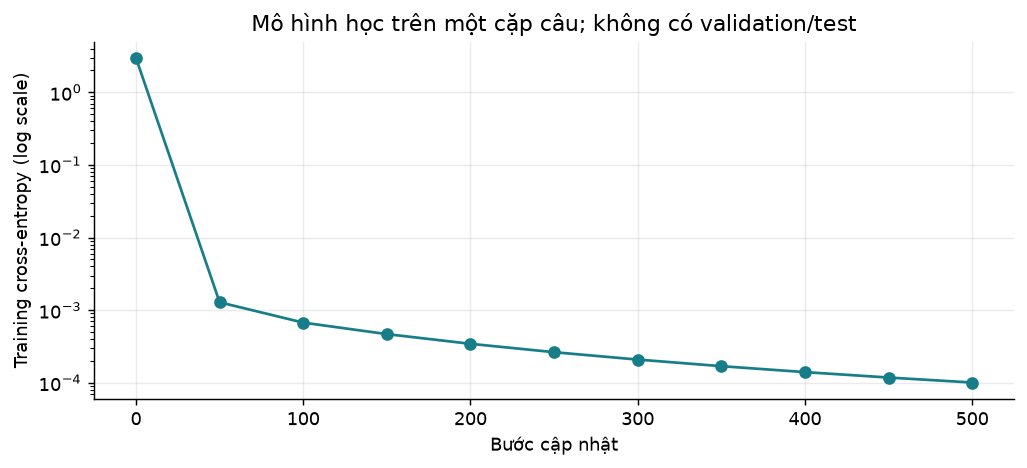

In [15]:
# ==============================================================================
# MỤC 12: THỰC THI HUẤN LUYỆN VÀ THEO DÕI ĐƯỜNG CONG HỘI TỤ CỦA LOSS
# ==============================================================================

@torch.no_grad()
def evaluate_training_pair(net):
    """
    Hàm đánh giá mất mát trên cặp câu huấn luyện ở chế độ suy luận:
    - @torch.no_grad(): Tắt đồ thị tính toán đạo hàm để tiết kiệm RAM và tăng tốc.
    - net.eval(): Chuyển mô hình sang chế độ đánh giá (tắt Dropout nếu có).
    - Tính Cross-Entropy Loss giữa logits và nhãn thực tế, loại trừ token đệm PAD.
    """
    net.eval()
    logits, _ = net(src, dec)
    # Làm phẳng (flatten) chiều batch và sequence để khớp định dạng của F.cross_entropy:
    # logits shape: (batch_size * seq_len, vocab_size) = (10, 13)
    # labels shape: (batch_size * seq_len,) = (10,)
    loss = F.cross_entropy(logits.reshape(-1, len(tgt_itos)), labels.reshape(-1), ignore_index=PAD)
    return float(loss)

# 1. Đo lường mất mát ban đầu trước khi cập nhật tham số (Bước 0)
#    Loss ban đầu xấp xỉ 2.5 ~ 2.6 (tương đương với mức đoán mò ngẫu nhiên -ln(1/13) ~ 2.565)
initial_loss = evaluate_training_pair(model)

# 2. Khởi tạo bộ tối ưu hóa Adam với tốc độ học LR = 0.01
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
history = [(0, initial_loss)]

# 3. Vòng lặp huấn luyện chính qua 500 bước (STEPS):
for step in range(1, STEPS + 1):
    # Bước a: Đặt mô hình ở chế độ huấn luyện
    model.train()

    # Bước b: Xóa sạch gradient tích lũy từ bước trước (set_to_none=True tối ưu bộ nhớ)
    optimizer.zero_grad(set_to_none=True)

    # Bước c: Forward pass - truyền câu nguồn và tiền tố đích để sinh Logits
    logits, _ = model(src, dec)

    # Bước d: Tính hàm mất mát Cross-Entropy giữa Logits và nhãn mục tiêu
    loss = F.cross_entropy(logits.reshape(-1, len(tgt_itos)), labels.reshape(-1), ignore_index=PAD)

    # Bước e: Backward pass - tính đạo hàm theo chuỗi phép toán qua Autograd
    loss.backward()

    # Bước f: Gradient Clipping - giới hạn chuẩn L2 của gradient ở mức tối đa 1.0
    nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

    # Bước g: Cập nhật các tham số mô hình thông qua thuật toán Adam
    optimizer.step()

    # Bước h: Ghi nhận lịch sử và hiển thị tiến trình định kỳ mỗi 50 bước
    if step % 50 == 0:
        current = evaluate_training_pair(model)
        history.append((step, current))
        print(f'Bước {step:3d} | training CE sau cập nhật = {current:.6f}')

# 4. Đánh giá mất mát cuối cùng sau 500 bước huấn luyện:
final_loss = evaluate_training_pair(model)
print(f'Trước học: {initial_loss:.6f} | Sau {STEPS} bước: {final_loss:.6f}')

# 5. Vẽ biểu đồ quá trình hội tụ của hàm mất mát theo thang Logarit (Log scale):
#    Đường cong dốc xuống đều đặn thể hiện mô hình đã hội tụ xuất sắc và học thuộc hoàn hảo cặp câu.
fig, ax = plt.subplots(figsize=(8, 3.7))
ax.semilogy(*zip(*history), marker='o', color='#177e89')
ax.set(xlabel='Bước cập nhật', ylabel='Training cross-entropy (log scale)',
       title='Mô hình học trên một cặp câu; không có validation/test')
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

## 13. Suy luận: sinh tiếng Anh từ `<bos>` đến `<eos>`

Khi sinh, hàm chỉ nhận **source IDs và model**, không nhận câu tham chiếu. Khởi đầu bằng `<bos>`, lấy hàng logits cuối, softmax trên vocabulary, chọn argmax, nối token vào prefix, lặp đến `<eos>` hoặc giới hạn 30 token. Đây là **greedy decoding**, không phải tra bảng từ/câu cố định.

Code không chặn thủ công các token vocabulary khi chọn argmax; nếu mô hình chưa học tốt thì vẫn có thể sinh token đặc biệt không phù hợp. Xác suất trong bảng là xác suất có điều kiện của token được chọn, **không phải xác suất toàn câu dịch đúng**. Dấu chấm và chữ hoa ở bản trình bày cuối được xử lý sau sinh, không phải kỹ năng đã học từ dữ liệu chữ thường không dấu câu.

In [16]:
@torch.no_grad()
def greedy_decode(net,source,max_new_tokens=30):
    net.eval()
    prefix=torch.tensor([[BOS]],dtype=torch.long,device=source.device)
    ids,trace=[],[]
    for step in range(max_new_tokens):
        logits,_=net(source,prefix)
        probs=logits[0,-1].softmax(dim=-1)
        next_id=int(probs.argmax())
        trace.append((step+1,tgt_itos[int(prefix[0,-1])],
                      tgt_itos[next_id],float(probs[next_id])))
        ids.append(next_id)
        prefix=torch.cat([prefix,torch.tensor([[next_id]],device=source.device)],dim=1)
        if next_id == EOS:
            break
    return ids,trace

generated_ids,trace=greedy_decode(model,src)
generated_words=[tgt_itos[j] for j in generated_ids if j not in (PAD,BOS,EOS)]
generated_text=' '.join(generated_words)
table(['Bước','Token cuối prefix','Token được chọn','Xác suất có điều kiện'],
      [(s,p,t,f'{v:.6f}') for s,p,t,v in trace])
print('Đầu ra token:',generated_text)
print('Đã gặp <eos>:',bool(generated_ids and generated_ids[-1] == EOS))
print('Bản trình bày:',generated_text[:1].upper()+generated_text[1:]+'.')
# Chỉ đối chiếu tham chiếu sau khi đã sinh, không truyền nó cho greedy_decode.
exact_match=(generated_ids == label_ids.tolist())
print('Khớp toàn bộ token của mẫu train, kể cả EOS:',exact_match)

Bước,Token cuối prefix,Token được chọn,Xác suất có điều kiện
1,<bos>,i,0.999906
2,i,am,0.999896
3,am,pursuing,0.999889
4,pursuing,a,0.999895
5,a,master's,0.999919
6,master's,degree,0.999905
7,degree,in,0.999918
8,in,information,0.999891
9,information,technology,0.999879
10,technology,<eos>,0.999893


Đầu ra token: i am pursuing a master's degree in information technology
Đã gặp <eos>: True
Bản trình bày: I am pursuing a master's degree in information technology.
Khớp toàn bộ token của mẫu train, kể cả EOS: True


## 14. Kiểm chứng mô hình và quan sát attention sau học

Token accuracy dưới teacher forcing dùng prefix đúng, còn exact match khi sinh tự hồi quy dùng prefix do mô hình sinh. Hai phép đo không giống nhau; cả hai bên dưới vẫn chỉ đo **mẫu huấn luyện**.

Kiểm tra rò thông tin: thay các token decoder input ở vị trí 3 trở đi, rồi so logits ở các vị trí 0–2. Nếu causal mask đúng, các logits đầu phải giữ nguyên trong sai số số học. Hình cross-attention lấy **từng head riêng**, dùng teacher forcing để có trục đầy đủ, không ngụ ý đây là căn chỉnh từ chính xác hay giải thích nhân quả.

Token accuracy trên mẫu train, có teacher forcing: 100.0%
Sai khác logits quá khứ khi đổi tương lai: 0.0
Cross-attention shape [batch,head,target,source]: (1, 4, 10, 10)


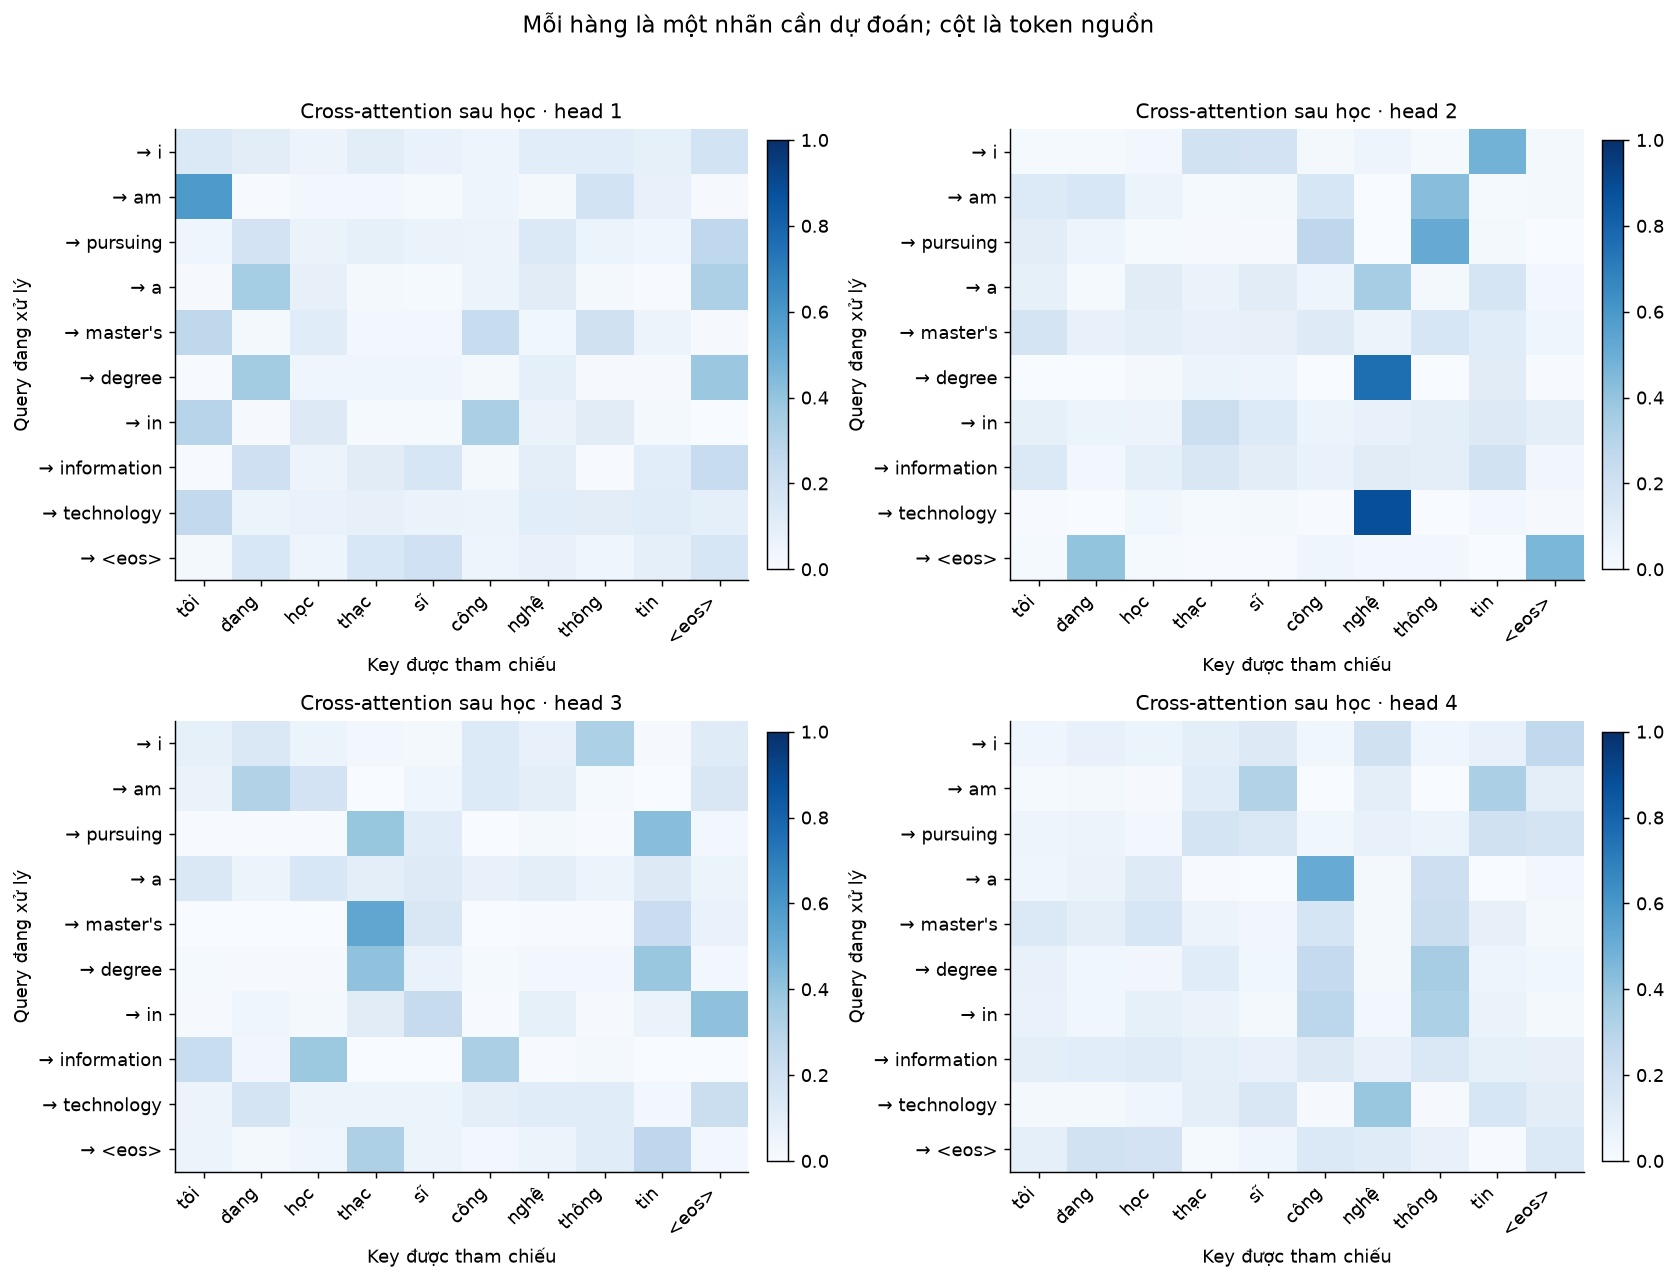

In [17]:
model.eval()
with torch.no_grad():
    trained_logits,trained_attn=model(src,dec)
    tf_accuracy=float(trained_logits.argmax(-1).eq(labels).float().mean())
    changed=dec.clone()
    changed[:,3:]=tgt_stoi['technology']
    changed_logits,_=model(src,changed)
    causal_difference=float((trained_logits[:,:3]-changed_logits[:,:3]).abs().max())
    causal=torch.triu(torch.ones(T,T,dtype=torch.bool),diagonal=1)
    self_weights=trained_attn['decoder'][0]  # [heads,T,T]
    assert torch.allclose(self_weights[:,causal],torch.zeros_like(self_weights[:,causal]),atol=1e-7)
    assert torch.allclose(self_weights.sum(-1),torch.ones_like(self_weights.sum(-1)),atol=1e-6)
    assert causal_difference < 1e-5
    assert final_loss < initial_loss
print('Token accuracy trên mẫu train, có teacher forcing:',f'{tf_accuracy:.1%}')
print('Sai khác logits quá khứ khi đổi tương lai:',causal_difference)
print('Cross-attention shape [batch,head,target,source]:',tuple(trained_attn['cross'].shape))

fig,axes=plt.subplots(2,2,figsize=(13,10))
for head,ax in enumerate(axes.flat):
    a=trained_attn['cross'][0,head].detach().cpu().numpy()
    heatmap(a,src_tokens,['→ '+w for w in label_tokens],f'Cross-attention sau học · head {head+1}',ax=ax)
fig.suptitle('Mỗi hàng là một nhãn cần dự đoán; cột là token nguồn',fontsize=13)
plt.tight_layout(rect=(0,0,1,.96)); plt.show()

## 15. Thí nghiệm chẩn đoán: mô hình dùng câu nguồn đến đâu?

Huấn luyện một mẫu có thể khiến decoder dựa nhiều vào prefix và vị trí để nhớ câu Anh. Ta thử: (1) nguồn gốc, (2) đảo các âm tiết, giữ EOS ở cuối, (3) thay toàn bộ nội dung bằng UNK, (4) đổi `tôi` thành UNK.

Nếu bản dịch vẫn giống khi nguồn bị phá, đó là dấu hiệu mô hình **có thể ghi nhớ chuỗi đích**; không kết luận nó dịch tốt. Nếu bản dịch đổi hoặc sai, điều đó cho thấy đầu ra nhạy với can thiệp ấy, vẫn chưa chứng minh hiểu nghĩa. Chỉ một số thử nghiệm can thiệp không đủ xác định toàn bộ cách mô hình sử dụng nguồn.

In [18]:
reversed_src=torch.cat([src[:,:-1].flip(1),src[:,-1:]],dim=1)
unknown_src=src.clone(); unknown_src[:,:-1]=UNK
first_unknown=src.clone(); first_unknown[:,0]=UNK
variants={'Nguồn gốc':src,'Đảo thứ tự âm tiết':reversed_src,
          'Toàn bộ nội dung = UNK':unknown_src,'Chỉ tôi = UNK':first_unknown}
diagnostics=[]
for name,variant in variants.items():
    pred,_=greedy_decode(model,variant)
    text=' '.join(tgt_itos[j] for j in pred if j not in (PAD,BOS,EOS))
    diagnostics.append((name,text,pred==label_ids.tolist(),bool(pred and pred[-1]==EOS)))
table(['Can thiệp nguồn','Câu sinh','Giống nhãn train','Có EOS'],diagnostics)

Can thiệp nguồn,Câu sinh,Giống nhãn train,Có EOS
Nguồn gốc,i am pursuing a master's degree in information technology,True,True
Đảo thứ tự âm tiết,i am pursuing a master's degree in information technology,True,True
Toàn bộ nội dung = UNK,i am pursuing a master's degree in information technology,True,True
Chỉ tôi = UNK,i am pursuing a master's degree in information technology,True,True


## 16. Lưu checkpoint và nạp lại để suy luận

Checkpoint lưu **state_dict + cấu hình + hai từ điển + lịch sử train**. Từ điển phải đi cùng trọng số vì thứ tự ID là một phần của mô hình. Không cần ghi vào Google Drive. Ô này tạo thư mục `artifacts_transformer_vi_en` cạnh thư mục làm việc hiện tại của kernel.

Khi nạp, các định nghĩa `TinyTranslator`, `EncoderBlock`, `DecoderBlock`, `positional_encoding` và hàm suy luận vẫn cần có trong kernel; đây không phải ô demo độc lập. Muốn tái tạo toàn bộ kết quả, cách đơn giản nhất là Run All, vì train rất nhỏ.

In [19]:
ARTIFACTS=Path('artifacts_transformer_vi_en')
ARTIFACTS.mkdir(exist_ok=True)
checkpoint_path=ARTIFACTS/'transformer_vi_en_demo.pt'
checkpoint={'state_dict':model.state_dict(),'config':CONFIG,
            'src_itos':src_itos,'tgt_itos':tgt_itos,'seed':SEED,
            'history':history,'source':SOURCE,'reference':REFERENCE}
torch.save(checkpoint,checkpoint_path)

loaded=torch.load(checkpoint_path,map_location=DEVICE,weights_only=True)
assert loaded['src_itos']==src_itos and loaded['tgt_itos']==tgt_itos
restored=TinyTranslator(len(loaded['src_itos']),len(loaded['tgt_itos']),**loaded['config']).to(DEVICE)
restored.load_state_dict(loaded['state_dict'])
restored.eval()
again,_=greedy_decode(restored,src)
assert again==generated_ids
print('Đã lưu và kiểm tra nạp lại:',checkpoint_path)
print('Sinh lại sau nạp khớp với kết quả trước lưu:',again==generated_ids)

Đã lưu và kiểm tra nạp lại: artifacts_transformer_vi_en\transformer_vi_en_demo.pt
Sinh lại sau nạp khớp với kết quả trước lưu: True


## 17. Tổng hợp thực nghiệm và nhận xét

Bảng tiếp theo được tính trực tiếp từ trạng thái đang chạy. Loss/PPL đo mức khớp dữ liệu huấn luyện; PPL bằng `exp(CE)` trên toàn bộ vocabulary. Không dùng BLEU trên một câu đã học để tuyên bố chất lượng dịch.

In [20]:
table(['Chỉ tiêu','Giá trị'],[
    ('Dữ liệu train','1 cặp câu Việt–Anh; không có validation/test'),
    ('Token nguồn/đích có ký hiệu kết thúc',f'{S} / {T}'),
    ('Vocabulary nguồn/đích',f'{len(src_itos)} / {len(tgt_itos)}'),
    ('Cấu hình',str(CONFIG)),
    ('Số bước / learning rate',f'{STEPS} / {LR}'),
    ('Training CE trước học',f'{initial_loss:.6f}'),
    ('Training CE sau học',f'{final_loss:.6f}'),
    ('Training PPL sau học',f'{math.exp(final_loss):.6f}'),
    ('Teacher-forcing token accuracy trên train',f'{tf_accuracy:.1%}'),
    ('Greedy exact match trên train, gồm EOS',str(exact_match)),
    ('Câu sinh thực tế',generated_text),
    ('Lưu/nạp checkpoint','Đã kiểm tra kết quả sinh khớp')])
if exact_match:
    print('Nhận xét từ lần chạy: mô hình ghi nhớ và sinh đúng cặp câu đã học.')
else:
    print('Nhận xét từ lần chạy: chưa sinh đúng toàn bộ mẫu train; xem bảng trace và loss.')
same_under_damage=any(row[2] for row in diagnostics[1:])
print('Có nguồn bị can thiệp nhưng vẫn cho cùng câu train:',same_under_damage)
print('Kết quả trên không cung cấp độ chính xác dịch cho câu mới.')

Chỉ tiêu,Giá trị
Dữ liệu train,1 cặp câu Việt–Anh; không có validation/test
Token nguồn/đích có ký hiệu kết thúc,10 / 10
Vocabulary nguồn/đích,13 / 13
Cấu hình,"{'d_model': 32, 'n_heads': 4, 'd_ff': 64, 'max_len': 64}"
Số bước / learning rate,500 / 0.01
Training CE trước học,2.959311
Training CE sau học,0.000101
Training PPL sau học,1.000101
Teacher-forcing token accuracy trên train,100.0%
"Greedy exact match trên train, gồm EOS",True


Nhận xét từ lần chạy: mô hình ghi nhớ và sinh đúng cặp câu đã học.
Có nguồn bị can thiệp nhưng vẫn cho cùng câu train: True
Kết quả trên không cung cấp độ chính xác dịch cho câu mới.


### 17.1. Thảo luận

**Vì sao cần cả encoder và decoder?** Encoder tạo memory cho câu nguồn; decoder dùng memory và prefix để dự đoán chuỗi đích. Bài toán dịch cần kết hợp thông tin câu nguồn với các token đích đã sinh để dự đoán token tiếp theo.

**Vì sao mô hình có thể sinh đúng dù attention chưa giống bản đồ dịch từng từ?** Mỗi encoder memory đã trộn ngữ cảnh; decoder có nhiều head và đường residual. Một cặp câu còn cho phép ghi nhớ vị trí/prefix. Vì thế không yêu cầu `master's` phải chú ý mạnh nhất vào riêng `thạc`, hoặc `technology` vào riêng `nghệ`.

**Vì sao training loss thấp chưa đủ?** Mô hình đã thấy cả câu Anh trong lúc học. Chưa có câu mới độc lập để đánh giá. Nếu thêm một cặp câu vào train rồi kiểm tra chính nó thì vẫn là đo trên train.

**Muốn xây dựng hệ thống dịch thực tế:** dùng nhiều cặp câu song ngữ, chia train/dev/test độc lập và tránh trùng lặp; học tokenizer chỉ từ dữ liệu phù hợp; chọn cấu hình/checkpoint bằng dev; báo cáo chỉ số dịch trên test cùng đánh giá thủ công. Cần kiểm tra độ đúng của chuyên ngành, mức học và thời của câu, không chỉ khớp từng từ.

### 17.2. Câu hỏi tự kiểm tra và đáp án ngắn

| Câu hỏi | Đáp án |
|---|---|
| ID và embedding khác nhau thế nào? | ID là chỉ số; embedding là vector tham số được tra theo ID. |
| Self-attention và cross-attention khác nhau ở đâu? | Self lấy Q/K/V cùng luồng; cross lấy Q từ decoder, K/V từ encoder. |
| Softmax attention chuẩn hóa chiều nào? | Theo các vị trí key, khác softmax đầu ra theo vocabulary. |
| Tại sao mask không chặn đường chéo? | Input đã dịch phải; token ở vị trí hiện tại thuộc prefix, chưa phải nhãn cần dự đoán. |
| Một head ở phần B có bao nhiêu chiều? | 32 / 4 = 8; scaling là căn 8. |
| Có thể suy ra chất lượng dịch từ exact match này không? | Chỉ biết mô hình sinh lại mẫu train; chưa biết chất lượng trên câu mới. |

## 18. Kết luận và tài liệu chuyên môn

Notebook hiện thực đầy đủ các thành phần của một Transformer encoder–decoder nhỏ: embedding, sinusoidal PE, self-attention, causal mask, cross-attention, FFN, residual, LayerNorm, output projection, cross-entropy, cập nhật gradient và greedy decoding. Bảng tổng hợp ở mục 17 ghi kết quả thực tế của lần chạy được lưu.

Với yêu cầu của bài, bản dịch tham chiếu là **“I am pursuing a master's degree in information technology.”** Quy trình này minh họa cơ chế sinh một câu tiếng Anh từ nguồn Việt và phân biệt rõ phép tính ngẫu nhiên, học tham số, ghi nhớ và tổng quát hóa.

**Nguồn học thuật và tài liệu kỹ thuật**

1. Vaswani et al. (2017), [Attention Is All You Need](https://arxiv.org/abs/1706.03762): nguồn kiến trúc attention encoder–decoder. Mô hình nhỏ này có số lớp và chiều thấp hơn bản đầy đủ trong bài báo.
2. PyTorch, [MultiheadAttention](https://docs.pytorch.org/docs/2.15/generated/torch.nn.MultiheadAttention.html): API attention và trả trọng số theo head; [CrossEntropyLoss](https://docs.pytorch.org/docs/2.15/generated/torch.nn.CrossEntropyLoss.html): loss từ logits và nhãn lớp.